# KoMaP 상(phase) 분할 — 데이터 탐색(EDA)

고탄성 주조용 알루미늄 합금의 광학 현미경 이미지를 4개 상으로 분할하는 과제의 데이터 분석 노트북입니다.
분석에서 나온 사실 하나하나를 **전처리·학습·후처리 결정의 근거**로 연결하는 것이 목적입니다.

| 상 | 마스크 색 (대회 정의) | 그래프 색 |
|---|---|---|
| Al | 갈색 `(153,127,76)` | 주황 |
| Al3Ni | 파랑 `(25,76,153)` | 파랑 |
| Primary Si (초정 Si) | 초록 `(76,178,76)` | 청록 |
| Eutectic Si (공정 Si) | 흰색 `(204,204,204)` | 보라 |

> 그래프 색은 마스크 색 계열을 따르되, 색각 이상자도 구분할 수 있도록 검증된 색으로 바꿨습니다. 마스크 이미지는 대회 공식 색 그대로 표시합니다.

**목차**
1. 데이터 구성
2. 이미지·마스크 기본 점검
3. 상별 면적 분포
4. 해상도와 배율
5. 밝기와 대비
6. 공정 Step별 차이
7. Primary Si가 없는 이미지
8. 상 사이의 인접 관계
9. 난이도 기준선과 상한
10. 기타 점검
11. 결론: 발견 → 결정

실행 환경: 프로젝트 `.venv` (numpy, pandas, matplotlib, opencv-python, pillow). 전체 실행에 수 분이 걸립니다.

In [1]:
import re
from pathlib import Path
import numpy as np, pandas as pd, cv2
from PIL import Image, ImageDraw
import matplotlib as mpl, matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage

ROOT = Path('..') if Path('../data').exists() else Path('.')
DATA, FIG = ROOT / 'data', ROOT / 'eda' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

CLASSES = ['Al', 'Al3Ni', 'Primary Si', 'Eutectic Si']
SHORT = ['Al', 'Al3Ni', 'SiP', 'SiE']
MASK_RGB = [(153, 127, 76), (25, 76, 153), (76, 178, 76), (204, 204, 204)]
PALETTE = {'Al': '#eb6834', 'Al3Ni': '#2a78d6', 'SiP': '#1baf7a', 'SiE': '#4a3aa7'}
INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'

mpl.rcParams.update({
    'font.family': 'Malgun Gothic', 'axes.unicode_minus': False,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False, 'legend.fontsize': 9,
    'figure.dpi': 90, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
})
pd.set_option('display.precision', 1)

In [2]:
PAT = re.compile(r'A(\d+)_step(\d)_sample(\d)')

def to_label(rgb):
    lab = np.full(rgb.shape[:2], 255, np.uint8)
    for i, c in enumerate(MASK_RGB):
        lab[(rgb == c).all(-1)] = i
    return lab

records = []
for split in ['train', 'valid', 'test']:
    for p in sorted((DATA / split / 'images').glob('*_image.png')):
        name = p.name.replace('_image.png', '')
        alloy, step, sample = map(int, PAT.match(name).groups())
        raw = np.array(Image.open(p))
        mp = DATA / split / 'masks' / f'{name}_mask.png'
        records.append(dict(
            split=split, name=name, alloy=alloy, step=step, sample=sample,
            H=raw.shape[0], W=raw.shape[1], mode=Image.open(p).mode,
            gray=np.array(Image.open(p).convert('L')),
            lab=to_label(np.array(Image.open(mp).convert('RGB'))) if mp.exists() else None,
            is_gray=bool((raw[..., 0] == raw[..., 1]).all() and (raw[..., 1] == raw[..., 2]).all()),
            alpha_full=bool(raw.shape[-1] < 4 or (raw[..., 3] == 255).all()),
        ))
labeled = [r for r in records if r['lab'] is not None]
BY_NAME = {r['name']: r for r in records}
meta = pd.DataFrame([{k: v for k, v in r.items() if k not in ('gray', 'lab')} for r in records])
meta['split'] = pd.Categorical(meta['split'], ['train', 'valid', 'test'], ordered=True)
meta['res'] = meta['W'].astype(str) + '×' + meta['H'].astype(str)

def colorize(lab):
    return np.array(MASK_RGB, np.uint8)[lab]

def miou(gt, pr):
    # 한 이미지에서 4개 상의 IoU. 정답과 예측 모두에 없는 상은 nan(평균에서 제외)
    out = []
    for c in range(4):
        u = np.logical_or(gt == c, pr == c).sum()
        out.append(np.logical_and(gt == c, pr == c).sum() / u if u else np.nan)
    return np.array(out)

def show_rows(names, fname, title, overlay=True, width=13):
    rows = [BY_NAME[n] for n in names]
    ncol = 3 if overlay else 2
    h = sum(r['H'] / r['W'] for r in rows) * width / ncol + 0.35 * len(rows) + 0.6
    fig, axes = plt.subplots(len(rows), ncol, figsize=(width, h), squeeze=False)
    for i, (axr, r) in enumerate(zip(axes, rows)):
        axr[0].imshow(r['gray'], cmap='gray', vmin=0, vmax=255)
        axr[0].set_title(f"{r['name']}  [{r['split']}, {r['W']}×{r['H']}]", fontsize=9, fontweight='normal', color=INK2)
        if r['lab'] is not None:
            axr[1].imshow(colorize(r['lab']))
            if overlay:
                axr[2].imshow(r['gray'], cmap='gray', vmin=0, vmax=255)
                axr[2].imshow(colorize(r['lab']), alpha=0.45)
        else:
            axr[1].text(0.5, 0.5, '정답 없음 (평가용)', ha='center', va='center', color=MUTED, transform=axr[1].transAxes)
        if i == 0:
            axr[1].set_title('정답 마스크', fontsize=9, fontweight='normal', color=INK2)
            if overlay: axr[2].set_title('겹쳐 보기', fontsize=9, fontweight='normal', color=INK2)
        for a in axr: a.axis('off')
    handles = [mpl.patches.Patch(facecolor=np.array(c) / 255, edgecolor=AXIS, label=n) for c, n in zip(MASK_RGB, CLASSES)]
    fig.legend(handles=handles, loc='upper right', ncol=4, fontsize=9)
    fig.suptitle(title, x=0.01, ha='left', fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, 0.985 - 0.25 / h))
    fig.savefig(FIG / fname)
    plt.show()

print(f'이미지 {len(records)}장, 정답 마스크 {len(labeled)}장 로드')

이미지 100장, 정답 마스크 90장 로드


## 1. 데이터 구성

파일명은 `A{합금번호}_step{공정 단계}_sample{시편 번호}` 형식입니다.

In [3]:
display(pd.crosstab(meta['split'], meta['res'], margins=True, margins_name='합계'))
display(pd.crosstab(meta['split'], 'step' + meta['step'].astype(str), margins=True, margins_name='합계'))

per_alloy = meta.groupby('alloy').size()
print(f"합금 수: {meta.alloy.nunique()}종 / 합금당 이미지 수 분포: {per_alloy.value_counts().sort_index().to_dict()}")
sets = {s: set(meta.loc[meta.split == s, 'alloy']) for s in ['train', 'valid', 'test']}
display(pd.DataFrame([
    {'조합': f'{a} ∩ {b}', '공유 합금 수': len(sets[a] & sets[b]),
     '합금 번호': ', '.join(f'A{x}' for x in sorted(sets[a] & sets[b]))}
    for a, b in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]]))

multi = meta[meta.alloy.isin(per_alloy[per_alloy > 1].index)].sort_values(['alloy', 'step', 'sample'])
display(pd.DataFrame([
    {'합금': f'A{a}', '이미지': ', '.join(f'step{r.step}/sample{r.sample} ({r.split})' for r in g.itertuples())}
    for a, g in multi.groupby('alloy')]))

res,1096×780,1230×875,1278×909,1440×1024,675×480,합계
split,,,,,,
train,0,20,24,9,17,70
valid,1,3,5,2,9,20
test,0,4,2,1,3,10
합계,1,27,31,12,29,100


step,step1,step2,step3,step4,합계
split,,,,,
train,13,18,12,27,70
valid,6,5,4,5,20
test,2,2,3,3,10
합계,21,25,19,35,100


합금 수: 77종 / 합금당 이미지 수 분포: {1: 56, 2: 19, 3: 2}


,조합,공유 합금 수,합금 번호
0,train ∩ valid,7,"A7, A40, A55, A125, A153, A181, A191"
1,train ∩ test,3,"A51, A87, A167"
2,valid ∩ test,1,A63


,합금,이미지
0,A7,"step1/sample2 (train), step1/sample4 (valid), ..."
1,A8,"step2/sample3 (train), step3/sample3 (train)"
2,A11,"step1/sample4 (valid), step2/sample4 (valid)"
3,A40,"step3/sample3 (valid), step3/sample4 (train)"
4,A51,"step3/sample3 (test), step4/sample4 (train)"
5,A55,"step2/sample1 (valid), step3/sample4 (train)"
6,A63,"step1/sample4 (valid), step2/sample3 (test)"
7,A87,"step1/sample4 (test), step2/sample2 (train)"
8,A111,"step1/sample2 (train), step3/sample4 (train)"
9,A123,"step1/sample1 (train), step4/sample2 (train)"


**해석**
- 해상도는 5종류지만 가로세로 비율(약 1.41)은 같습니다. 4절에서 **같은 시야를 해상도만 다르게 찍은 것**임을 확인합니다.
- 합금 77종 중 21종은 2~3장이 있고, 일부는 학습·검증·평가 세트에 걸쳐 있습니다. 같은 합금의 사진은 분위기가 비슷하므로 **교차검증은 합금 번호 단위로 나눠야** 점수가 부풀지 않습니다.

## 2. 이미지·마스크 기본 점검

In [4]:
def boundary(lab):
    b = np.zeros(lab.shape, bool)
    b[:, 1:] |= lab[:, 1:] != lab[:, :-1]
    b[1:, :] |= lab[1:, :] != lab[:-1, :]
    return b

# 마스크 경계를 ±3픽셀 옮겨 보며 이미지 윤곽과 가장 잘 맞는 위치를 찾음. (0,0)이 최적이면 정렬 정상
align = []
for r in labeled:
    bd = boundary(r['lab'])
    g = r['gray'].astype(np.float32)
    gm = cv2.magnitude(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))[5:-5, 5:-5]
    sc = {(dy, dx): gm[np.roll(bd, (dy, dx), (0, 1))[5:-5, 5:-5]].mean() for dy in range(-3, 4) for dx in range(-3, 4)}
    best = max(sc, key=sc.get)
    align.append(best != (0, 0) and sc[best] / sc[(0, 0)] > 1.02)

display(pd.DataFrame({
    '점검 항목': ['저장 형식', '실제로 흑백(R=G=B)인 이미지', '알파 채널이 모두 불투명', '마스크에 4색 외 다른 색',
              '이미지·마스크 크기 일치', '마스크가 이미지와 어긋난 사진'],
    '결과': [', '.join(meta['mode'].unique()), f"{meta.is_gray.sum()}/{len(meta)}", f"{meta.alpha_full.sum()}/{len(meta)}",
           f"{sum(int((r['lab'] == 255).sum()) for r in labeled)} 픽셀",
           f"{sum(r['lab'].shape == r['gray'].shape for r in labeled)}/{len(labeled)}",
           f"{sum(align)}/{len(labeled)}"]}))

,점검 항목,결과
0,저장 형식,RGBA
1,실제로 흑백(R=G=B)인 이미지,100/100
2,알파 채널이 모두 불투명,100/100
3,마스크에 4색 외 다른 색,0 픽셀
4,이미지·마스크 크기 일치,90/90
5,마스크가 이미지와 어긋난 사진,0/90


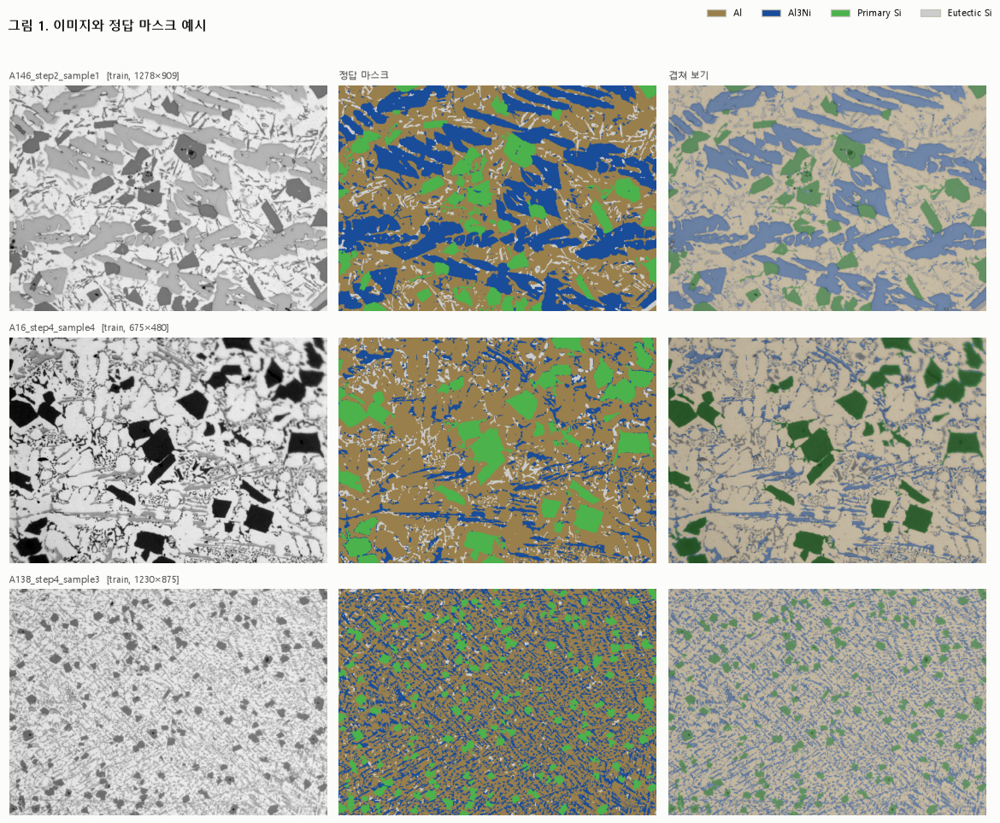

In [5]:
show_rows(['A146_step2_sample1', 'A16_step4_sample4', 'A138_step4_sample3'], 'fig01_samples.png',
          '그림 1. 이미지와 정답 마스크 예시')

**해석**
- RGBA로 저장돼 있지만 실제로는 모두 흑백입니다. 모델 입력은 1채널로 충분합니다. 사전학습 인코더를 쓸 때만 3채널로 복제합니다.
- 마스크는 정확히 4색이고, 이미지와 어긋난 사진도 없습니다. **라벨 정제 작업은 필요 없습니다.**
- 마스크 색과 실제 밝기는 다릅니다. 마스크에서 "흰색"인 Eutectic Si는 현미경 사진에서 **어두운 바늘 모양**입니다.

## 3. 상별 면적 분포

,전체 픽셀 비율(%),이미지별 평균(%),최소(%),최대(%),이 상이 없는 이미지
Al,58.0,58.7,41.1,75.5,0
Al3Ni,25.3,24.0,7.5,43.3,0
Primary Si,9.6,9.9,0.0,22.6,2
Eutectic Si,7.1,7.4,0.9,18.0,0


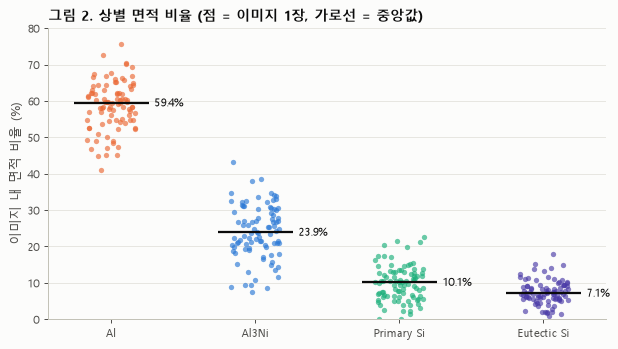

In [6]:
ratio = pd.DataFrame([{'name': r['name'], 'split': r['split'], 'step': r['step'], 'W': r['W'],
                       **{SHORT[c]: (r['lab'] == c).mean() * 100 for c in range(4)}} for r in labeled])
px = pd.Series({s: sum(int((r['lab'] == c).sum()) for r in labeled) for c, s in enumerate(SHORT)})
summary = pd.DataFrame({
    '전체 픽셀 비율(%)': px / px.sum() * 100, '이미지별 평균(%)': ratio[SHORT].mean(),
    '최소(%)': ratio[SHORT].min(), '최대(%)': ratio[SHORT].max(), '이 상이 없는 이미지': (ratio[SHORT] == 0).sum()})
summary.index = CLASSES
display(summary)

fig, ax = plt.subplots(figsize=(8, 4.2))
rng = np.random.default_rng(0)
for i, s in enumerate(SHORT):
    v = ratio[s].values
    ax.scatter(i + rng.uniform(-0.17, 0.17, len(v)), v, s=18, color=PALETTE[s], alpha=0.65, linewidths=0)
    med = np.median(v)
    ax.hlines(med, i - 0.26, i + 0.26, color=INK, linewidth=1.8)
    ax.text(i + 0.3, med, f'{med:.1f}%', va='center', fontsize=9, color=INK)
ax.set_xticks(range(4), CLASSES)
ax.set_ylabel('이미지 내 면적 비율 (%)')
ax.set_ylim(0, 80)
ax.grid(axis='x', visible=False)
ax.set_title('그림 2. 상별 면적 비율 (점 = 이미지 1장, 가로선 = 중앙값)')
fig.savefig(FIG / 'fig02_class_ratio.png'); plt.show()

**해석**
- Al이 약 58%로 가장 많고, Eutectic Si는 약 7%로 가장 적습니다. mIoU는 4개 상을 **똑같은 비중으로 평균**하므로, 면적이 작은 상을 틀려도 점수가 크게 떨어집니다.
- Primary Si가 아예 없는 이미지가 2장 있습니다. 7절에서 따로 다룹니다.

## 4. 해상도와 배율

해상도가 다른 사진이 같은 배율(시야)을 찍은 것인지 확인합니다. 물체 크기를 **사진 가로 길이 대비 비율**로 재서 비교합니다.

In [7]:
def ridge_widths(mask):
    # 구조의 중심선에서 잰 두께(픽셀): 거리변환의 국소 최댓값 × 2
    b = np.pad(mask.astype(np.uint8), 1, constant_values=1)
    dt = cv2.distanceTransform(b, cv2.DIST_L2, 3)[1:-1, 1:-1]
    ridge = (dt > 0) & (dt >= cv2.dilate(dt, np.ones((3, 3), np.uint8)))
    return 2 * dt[ridge]

def rel_size(mask, W):
    _, _, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    a = st[1:, 4]; a = a[a >= 3]
    return np.sqrt(np.median(a)) / W * 1000 if len(a) else np.nan

rows, widths = [], {}
for r in labeled:
    rows.append({'W': r['W'], 'SiP 상대 크기': rel_size(r['lab'] == 2, r['W']), 'SiE 상대 크기': rel_size(r['lab'] == 3, r['W'])})
    for c in (1, 3):
        widths.setdefault((r['W'], c), []).append(ridge_widths(r['lab'] == c))
scale = pd.DataFrame(rows).groupby('W').agg(['mean'])
scale.columns = [a for a, _ in scale.columns]
scale.insert(0, '이미지 수', pd.DataFrame(rows).groupby('W').size())
for c, s in [(1, 'Al3Ni'), (3, 'SiE')]:
    scale[f'{s} 두께 중앙값(px)'] = [np.median(np.concatenate(widths[(w, c)])) for w in scale.index]
    scale[f'{s} 2px 이하(%)'] = [np.mean(np.concatenate(widths[(w, c)]) <= 2) * 100 for w in scale.index]
scale.index.name = '가로(px)'
display(scale)

big = []
for r in labeled:
    k, _, st, _ = cv2.connectedComponentsWithStats((r['lab'] == 2).astype(np.uint8), connectivity=8)
    if k > 1:
        j = 1 + np.argmax(st[1:, 4]); big.append(max(st[j, 2], st[j, 3]))
print(f'이미지별 가장 큰 Primary Si 덩어리의 긴 변: 중앙값 {np.median(big):.0f}px, 최대 {np.max(big)}px')

,이미지 수,SiP 상대 크기,SiE 상대 크기,Al3Ni 두께 중앙값(px),Al3Ni 2px 이하(%),SiE 두께 중앙값(px),SiE 2px 이하(%)
가로(px),,,,,,,
675,26,50.1,6.5,1.9,70.8,1.9,75.2
1096,1,41.4,5.2,1.9,55.1,1.9,60.0
1230,23,61.2,5.7,2.7,45.9,2.7,40.4
1278,29,38.3,5.9,2.7,42.1,3.8,34.9
1440,11,59.5,6.4,3.8,33.7,3.8,18.0


이미지별 가장 큰 Primary Si 덩어리의 긴 변: 중앙값 194px, 최대 523px


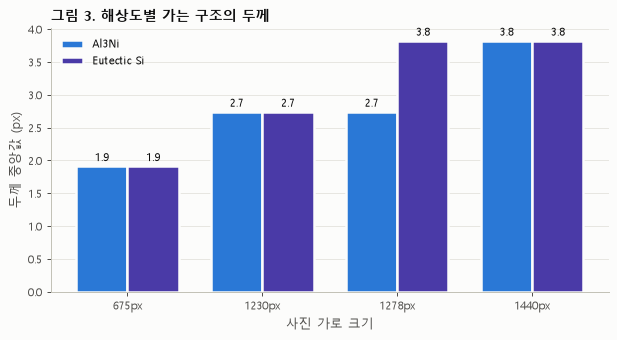

In [8]:
ws = [675, 1230, 1278, 1440]
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(ws)); bw = 0.38
for k, (c, s) in enumerate([(1, 'Al3Ni'), (3, 'SiE')]):
    v = [scale.loc[w, f'{s} 두께 중앙값(px)'] for w in ws]
    bars = ax.bar(x + (k - 0.5) * bw, v, bw, color=PALETTE[s], edgecolor=SURFACE, linewidth=2, label=CLASSES[c])
    for b, val in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, val + 0.08, f'{val:.1f}', ha='center', fontsize=9, color=INK)
ax.set_xticks(x, [f'{w}px' for w in ws])
ax.set_xlabel('사진 가로 크기'); ax.set_ylabel('두께 중앙값 (px)')
ax.grid(axis='x', visible=False); ax.legend(loc='upper left')
ax.set_title('그림 3. 해상도별 가는 구조의 두께')
fig.savefig(FIG / 'fig03_thickness.png'); plt.show()

**해석**
- 물체의 상대 크기는 해상도와 상관없이 비슷합니다. 즉 **같은 시야를 해상도만 다르게 찍은 것**입니다.
- 675px 사진에서는 Al3Ni와 Eutectic Si의 두께가 **약 2픽셀**이고, 70% 이상이 2픽셀 이하입니다. 1픽셀만 틀려도 IoU가 크게 떨어집니다.
  (두께는 거리변환으로 잰 근사값이라 1.9 / 2.7 / 3.8처럼 계단식 값으로 나옵니다.)
- **결정:** 모든 사진을 같은 배율로 맞춰 처리합니다. 작은 사진은 키워서 예측하고 원래 크기로 되돌립니다.
- 가장 큰 Primary Si는 한 변이 500px를 넘으므로, **학습 조각(crop)은 512px 이상**으로 잡습니다.

## 5. 밝기와 대비

In [9]:
for r in records:
    r['p1'], r['p99'] = np.percentile(r['gray'], [1, 99])
    r['style'] = '저대비' if r['p1'] > 60 else '고대비'
meta['p1'] = [r['p1'] for r in records]; meta['style'] = [r['style'] for r in records]

cls_gray = pd.DataFrame([{CLASSES[c]: r['gray'][r['lab'] == c].mean() for c in range(4) if (r['lab'] == c).any()} for r in labeled])
display(cls_gray.describe().loc[['mean', 'min', 'max']].rename(index={'mean': '평균 밝기', 'min': '최소', 'max': '최대'}))

style = pd.crosstab(meta['split'], meta['style'])
style['저대비 비율(%)'] = style['저대비'] / style.sum(axis=1) * 100
display(style)
print('평가용 저대비 이미지:', ', '.join(meta.loc[(meta.split == 'test') & (meta['style'] == '저대비'), 'name']))

,Al,Al3Ni,Primary Si,Eutectic Si
평균 밝기,211.5,137.9,58.9,94.2
최소,182.6,81.9,16.7,30.6
최대,231.1,184.9,122.6,149.0


style,고대비,저대비,저대비 비율(%)
split,,,
train,47,23,32.9
valid,15,5,25.0
test,4,6,60.0


평가용 저대비 이미지: A107_step1_sample3, A122_step4_sample1, A124_step4_sample3, A127_step3_sample2, A133_step4_sample1, A63_step2_sample3


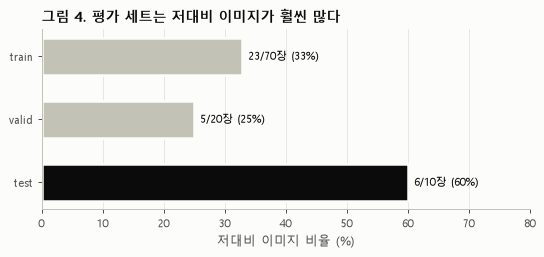

In [10]:
fig, ax = plt.subplots(figsize=(7, 2.6))
order = ['train', 'valid', 'test']
vals = [style.loc[s, '저대비 비율(%)'] for s in order]
bars = ax.barh(order[::-1], vals[::-1], color=[INK if s == 'test' else AXIS for s in order[::-1]], edgecolor=SURFACE, linewidth=2, height=0.6)
for b, s in zip(bars, order[::-1]):
    n_low, n = style.loc[s, '저대비'], style.loc[s, ['저대비', '고대비']].sum()
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f'{n_low}/{n}장 ({b.get_width():.0f}%)', va='center', fontsize=9, color=INK)
ax.set_xlim(0, 80); ax.set_xlabel('저대비 이미지 비율 (%)')
ax.grid(axis='y', visible=False)
ax.set_title('그림 4. 평가 세트는 저대비 이미지가 훨씬 많다')
fig.savefig(FIG / 'fig04_contrast_by_split.png'); plt.show()

대비가 낮은 사진에서는 Primary Si가 회색으로, 높은 사진에서는 검은색으로 보입니다.
사진마다 **가장 어두운 1%를 0, 가장 밝은 1%를 255로 늘리는 정규화**(p1–p99)를 하면 두 스타일의 차이가 얼마나 줄어드는지 확인합니다.

In [11]:
rows = []
for r in labeled:
    gn = np.clip((r['gray'].astype(float) - r['p1']) / (r['p99'] - r['p1']) * 255, 0, 255)
    for c in range(4):
        m = r['lab'] == c
        if m.any():
            rows.append({'style': r['style'], '상': CLASSES[c], '원본': r['gray'][m].mean(), '정규화 후': gn[m].mean()})
norm = pd.DataFrame(rows).groupby(['상', 'style'])[['원본', '정규화 후']].mean().unstack('style')
norm = norm.reindex(CLASSES)
for k in ['원본', '정규화 후']:
    norm[(k, '스타일 간 차이')] = (norm[(k, '저대비')] - norm[(k, '고대비')]).abs()
display(norm[[('원본', '저대비'), ('원본', '고대비'), ('원본', '스타일 간 차이'),
              ('정규화 후', '저대비'), ('정규화 후', '고대비'), ('정규화 후', '스타일 간 차이')]])

원본                  정규화 후                
style          저대비    고대비 스타일 간 차이    저대비    고대비 스타일 간 차이
상                                                        
Al           218.0  208.6      9.4  218.4  217.1      1.2
Al3Ni        160.4  127.7     32.6  125.3  127.1      1.8
Primary Si    95.8   41.7     54.1   22.6   31.5      8.9
Eutectic Si  127.7   79.1     48.6   72.7   73.4      0.6

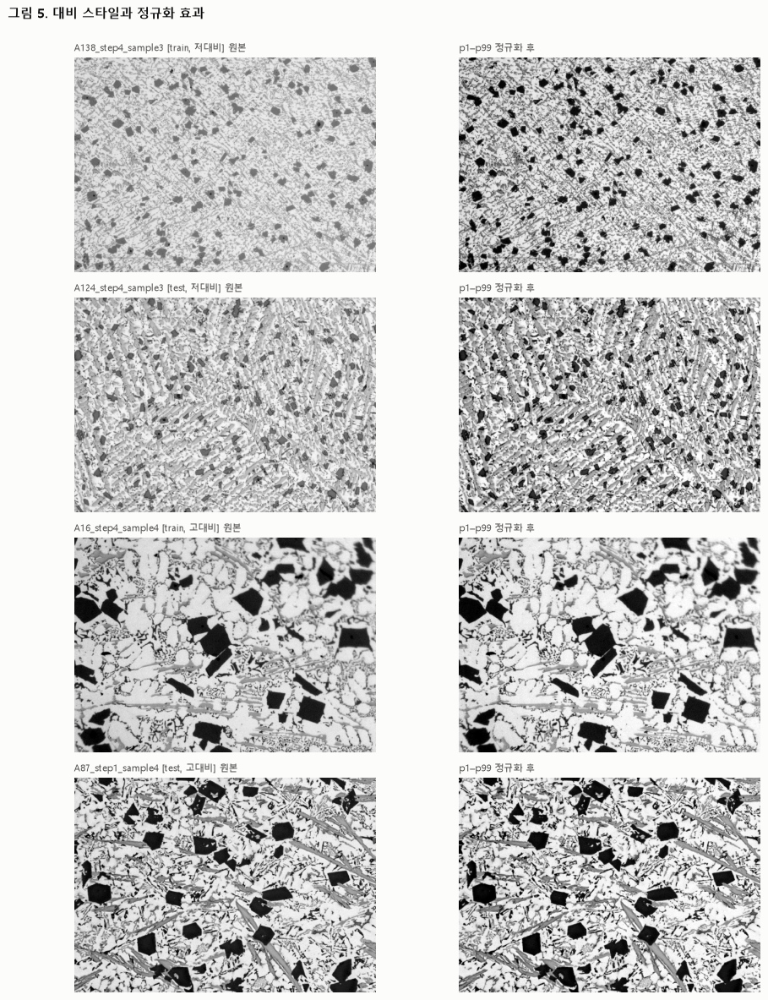

In [12]:
names = ['A138_step4_sample3', 'A124_step4_sample3', 'A16_step4_sample4', 'A87_step1_sample4']
fig, axes = plt.subplots(len(names), 2, figsize=(11, 3.95 * len(names) * 11 / 13))
for axr, n in zip(axes, names):
    r = BY_NAME[n]
    gn = np.clip((r['gray'].astype(float) - r['p1']) / (r['p99'] - r['p1']) * 255, 0, 255)
    axr[0].imshow(r['gray'], cmap='gray', vmin=0, vmax=255)
    axr[1].imshow(gn, cmap='gray', vmin=0, vmax=255)
    axr[0].set_title(f"{n} [{r['split']}, {r['style']}] 원본", fontsize=9, fontweight='normal', color=INK2)
    axr[1].set_title('p1–p99 정규화 후', fontsize=9, fontweight='normal', color=INK2)
    for a in axr: a.axis('off')
fig.suptitle('그림 5. 대비 스타일과 정규화 효과', x=0.01, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(FIG / 'fig05_contrast_styles.png'); plt.show()

In [13]:
# 조명 불균일: 같은 Al(바탕) 영역의 밝기를 가운데와 네 모서리에서 비교
rows = []
for r in labeled:
    g, al = r['gray'].astype(float), r['lab'] == 0
    H, W = g.shape
    center = g[H // 3:2 * H // 3, W // 3:2 * W // 3][al[H // 3:2 * H // 3, W // 3:2 * W // 3]].mean()
    corners = [g[ys, xs][al[ys, xs]].mean() for ys in (slice(0, H // 4), slice(-H // 4, None)) for xs in (slice(0, W // 4), slice(-W // 4, None))]
    rows.append({'name': r['name'], '모서리-가운데(최저)': min(corners) - center, '모서리끼리 차이': max(corners) - min(corners)})
vig = pd.DataFrame(rows)
print(f"모서리-가운데 밝기 차 중앙값: {vig['모서리-가운데(최저)'].median():+.1f} (Al 평균 밝기 약 {cls_gray['Al'].mean():.0f})")
display(vig.sort_values('모서리-가운데(최저)').head(5).set_index('name'))

모서리-가운데 밝기 차 중앙값: -10.5 (Al 평균 밝기 약 212)


,모서리-가운데(최저),모서리끼리 차이
name,,
A188_step4_sample1,-28.4,28.3
A167_step3_sample4,-26.1,36.4
A182_step4_sample3,-24.8,23.0
A164_step4_sample1,-23.9,28.7
A18_step2_sample1,-21.7,19.9


**해석**
- 같은 상이라도 사진마다 밝기 차이가 큽니다. 예를 들어 Al3Ni는 사진에 따라 약 80~185입니다. **고정된 밝기 기준으로는 상을 나눌 수 없습니다.**
- 학습·검증 세트에서는 저대비 사진이 25~33%인데, **평가 세트는 60%**입니다. 검증 점수가 평가 점수를 대표하지 못할 수 있습니다.
- p1–p99 정규화를 하면 두 스타일 간 상별 밝기 차이가 크게 줄어듭니다. Al3Ni와 Eutectic Si는 차이가 거의 사라집니다.
- 모서리가 가운데보다 어두운 조명 불균일이 있습니다(중앙값 약 −10, 심한 사진은 약 −28).
- **결정:**
  - p1–p99 정규화를 기본 전처리로 씁니다.
  - 대비 낮추기와 조명 기울기 증강을 넣습니다.
  - 검증 점수는 저대비 사진만 따로도 계산합니다.

## 6. 공정 Step별 차이

Step의 정확한 의미는 데이터에 없습니다. 먼저 전체를 Step별로 비교하고, 합금 조성 차이를 없애기 위해 **같은 합금끼리 Step만 다른 쌍**도 비교합니다.

In [14]:
ratio['contrast'] = [r['gray'].std() for r in labeled]
by_step = ratio.groupby('step')[SHORT + ['contrast']].agg(['mean', 'std'])
by_step.insert(0, ('이미지 수', ''), ratio.groupby('step').size())
display(by_step)

ratio['alloy'] = [r['alloy'] for r in labeled]
pairs = []
for a, g in ratio.groupby('alloy'):
    e, l = g[g.step <= 2], g[g.step >= 3]
    if len(e) and len(l):
        pairs.append({'합금': f'A{a}', 'early': ', '.join(f'step{s}' for s in e.step), 'late': ', '.join(f'step{s}' for s in l.step),
                      **{f'{s} early': e[s].mean() for s in SHORT}, **{f'{s} late': l[s].mean() for s in SHORT}})
pairs = pd.DataFrame(pairs)
for s in SHORT:
    pairs[f'Δ{s}'] = pairs[f'{s} late'] - pairs[f'{s} early']
display(pairs[['합금', 'early', 'late'] + [f'Δ{s}' for s in SHORT]].set_index('합금'))
display(pd.DataFrame({'평균 변화(%p)': [pairs[f'Δ{s}'].mean() for s in SHORT],
                      '증가한 쌍': [f"{(pairs[f'Δ{s}'] > 0).sum()}/{len(pairs)}" for s in SHORT]}, index=CLASSES))

이미지 수    Al      Al3Ni        SiP       SiE      contrast      
            mean  std  mean  std  mean  std mean  std     mean   std
step                                                                
1       19  59.5  7.5  21.2  8.3  10.3  5.6  9.0  3.5     62.4  14.3
2       23  59.8  6.2  20.8  6.6  11.0  5.9  8.4  3.0     62.4  11.9
3       16  58.0  7.0  26.2  5.8   9.7  4.4  6.1  2.8     61.1  11.0
4       32  57.8  6.5  26.9  6.8   8.9  3.8  6.4  3.1     54.0  10.9

,early,late,ΔAl,ΔAl3Ni,ΔSiP,ΔSiE
합금,,,,,,
A7,"step1, step1",step4,-5.1,13.5,-6.6,-1.8
A8,step2,step3,-5.2,0.7,5.3,-0.9
A55,step2,step3,-0.5,6.0,-3.2,-2.3
A111,step1,step3,-6.9,3.6,4.6,-1.2
A123,step1,step4,9.5,-1.0,-8.0,-0.4
A153,step1,step3,3.5,5.0,-0.6,-8.0
A164,step1,step4,-8.1,2.1,2.0,4.0
A181,step1,step4,0.2,6.4,-1.7,-4.9
A187,step2,step4,4.7,2.9,-4.0,-3.6


,평균 변화(%p),증가한 쌍
Al,-0.7,5/10
Al3Ni,4.7,9/10
Primary Si,-1.5,3/10
Eutectic Si,-2.5,1/10


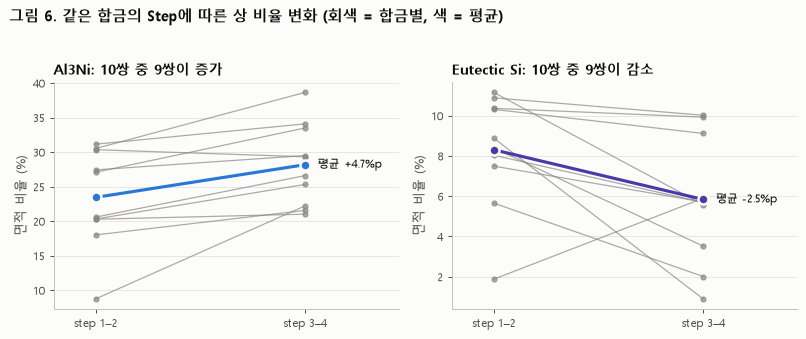

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=False)
for ax, s, c in [(axes[0], 'Al3Ni', 1), (axes[1], 'SiE', 3)]:
    for _, p in pairs.iterrows():
        ax.plot([0, 1], [p[f'{s} early'], p[f'{s} late']], color=MUTED, linewidth=1, alpha=0.7, marker='o', markersize=4)
    m0, m1 = pairs[f'{s} early'].mean(), pairs[f'{s} late'].mean()
    ax.plot([0, 1], [m0, m1], color=PALETTE[s], linewidth=2.5, marker='o', markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.text(1.06, m1, f'평균 {m1 - m0:+.1f}%p', va='center', fontsize=9, color=INK)
    up = (pairs[f'Δ{s}'] > 0).sum()
    ax.set_title(f"{CLASSES[c]}: {len(pairs)}쌍 중 {up if m1 > m0 else len(pairs) - up}쌍이 {'증가' if m1 > m0 else '감소'}")
    ax.set_xticks([0, 1], ['step 1–2', 'step 3–4']); ax.set_xlim(-0.2, 1.45)
    ax.set_ylabel('면적 비율 (%)'); ax.grid(axis='x', visible=False)
fig.suptitle('그림 6. 같은 합금의 Step에 따른 상 비율 변화 (회색 = 합금별, 색 = 평균)', x=0.01, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIG / 'fig06_step_paired.png'); plt.show()

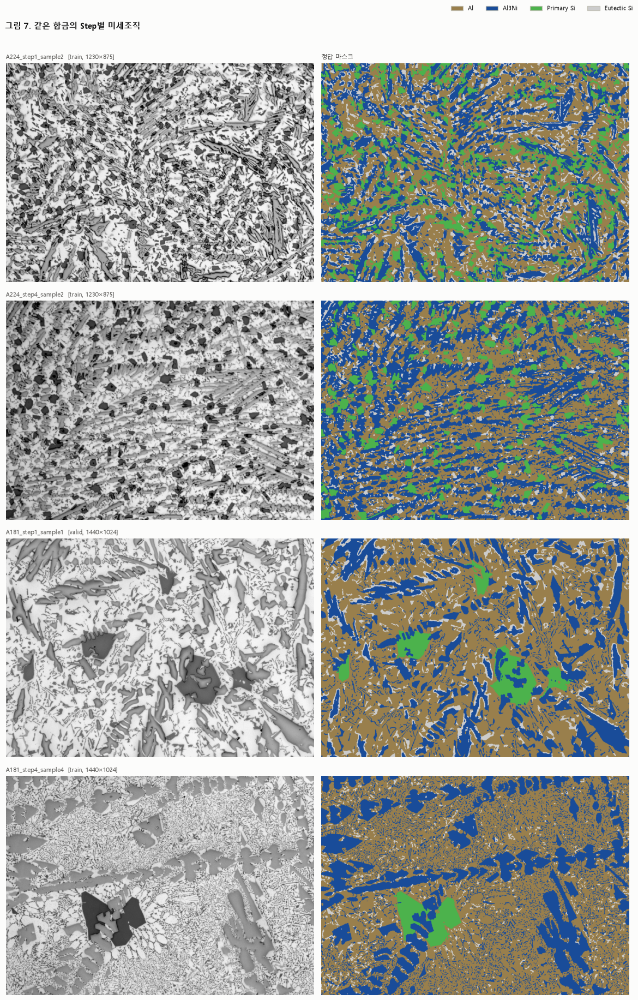

In [16]:
show_rows(['A224_step1_sample2', 'A224_step4_sample2', 'A181_step1_sample1', 'A181_step4_sample4'], 'fig07_step_examples.png',
          '그림 7. 같은 합금의 Step별 미세조직', overlay=False)

**해석**
- 같은 합금끼리 비교하면 Step 3·4로 갈수록 **Al3Ni가 늘고, Eutectic Si가 줄어드는** 경향이 일관되게 나타납니다. 대비도 대체로 낮아집니다.
- 하지만 같은 Step 안의 편차(표준편차 약 6~8%p)가 Step 간 차이보다 큽니다. **Step별로 모델을 따로 만들 필요는 없습니다.**
- **활용:**
  - 검증 점수를 Step별로도 확인합니다.
  - 평가 이미지 파일명에도 Step이 있으니, 모델에 Step을 힌트로 넣는 실험을 해볼 수 있습니다.
  - "공정 단계에 따른 상 분율 변화"는 보고서 인사이트로 활용할 수 있습니다.

## 7. Primary Si가 없는 이미지

Primary Si가 없는 이미지: ['A57_step1_sample3', 'A71_step2_sample1']


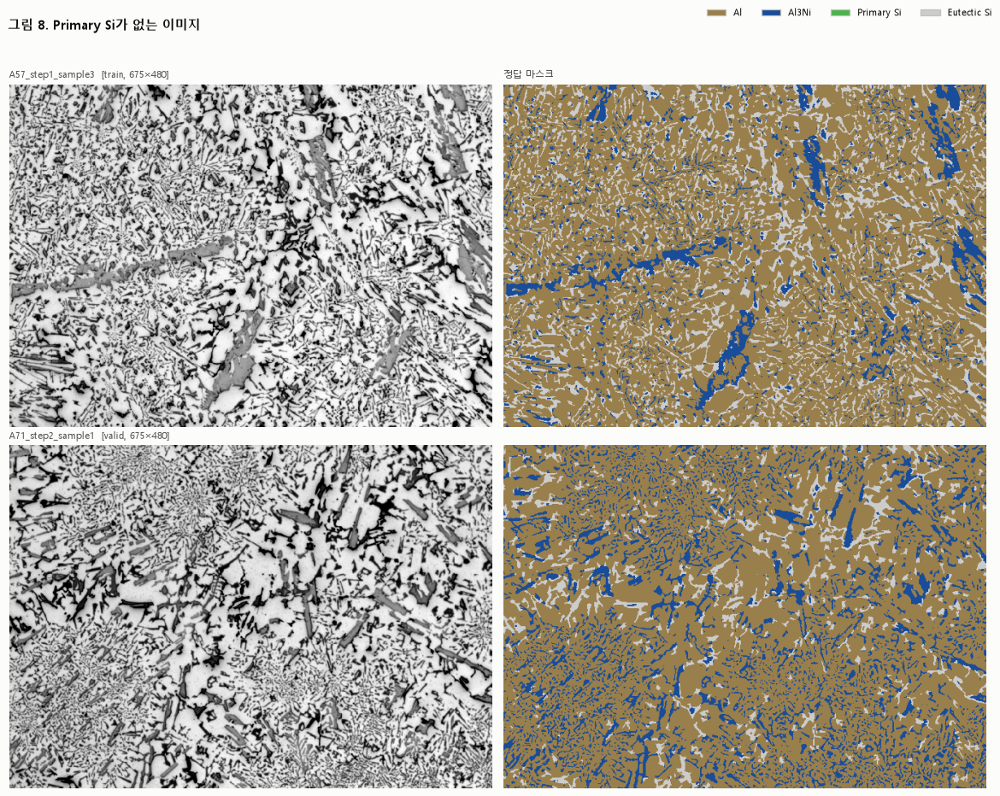

In [17]:
absent = [r['name'] for r in labeled if not (r['lab'] == 2).any()]
print('Primary Si가 없는 이미지:', absent)
show_rows(absent, 'fig08_no_primary_si.png', '그림 8. Primary Si가 없는 이미지', overlay=False)

In [18]:
# 위험도: 정답에 없는 Primary Si를 n픽셀만 잘못 칠했을 때 그 이미지의 mIoU
rows = []
for n in absent:
    r = BY_NAME[n]
    ys, xs = np.where(r['lab'] == 3)
    for k in [0, 50, 500, 5000]:
        pr = r['lab'].copy(); pr[ys[:k], xs[:k]] = 2
        rows.append({'이미지': n, '잘못 칠한 픽셀': k, '이미지 면적 대비(%)': k / r['lab'].size * 100, 'mIoU(%)': np.nanmean(miou(r['lab'], pr)) * 100})
display(pd.DataFrame(rows).pivot(index='잘못 칠한 픽셀', columns='이미지', values='mIoU(%)'))

# 후처리 기준 정하기: 작은 Primary Si 조각을 지우면 정답 픽셀을 얼마나 잃는가
areas = []
for r in labeled:
    _, _, st, _ = cv2.connectedComponentsWithStats((r['lab'] == 2).astype(np.uint8), connectivity=8)
    areas += list(st[1:, 4] / r['lab'].size * 100)
areas = np.array(areas)
display(pd.DataFrame([{'조각 크기 기준(이미지 면적 %)': t, '해당 조각 수': int((areas < t).sum()),
                       '잃는 Primary Si 픽셀(%)': areas[areas < t].sum() / areas.sum() * 100}
                      for t in [0.001, 0.005, 0.01, 0.02, 0.05]]).set_index('조각 크기 기준(이미지 면적 %)')
        .style.format({'잃는 Primary Si 픽셀(%)': '{:.3f}'}).format_index('{:.3f}'))
present = ratio.loc[ratio.SiP > 0, ['name', 'SiP']].nsmallest(5, 'SiP')
print('Primary Si가 있는 이미지 중 면적이 가장 작은 5장:'); display(present.set_index('name'))

이미지,A57_step1_sample3,A71_step2_sample1
잘못 칠한 픽셀,,
0,100.0,100.0
50,75.0,74.9
500,74.8,74.5
5000,72.9,69.8


,해당 조각 수,잃는 Primary Si 픽셀(%)
조각 크기 기준(이미지 면적 %),,
0.001,80,0.003
0.005,130,0.017
0.010,143,0.028
0.020,227,0.180
0.050,888,2.880


Primary Si가 있는 이미지 중 면적이 가장 작은 5장:


,SiP
name,
A111_step1_sample2,1.5
A123_step4_sample2,2.3
A181_step4_sample4,2.4
A125_step2_sample1,2.4
A191_step4_sample1,3.1


**해석**
- 두 이미지 모두 라벨 실수가 아닙니다. 각진 Primary Si 덩어리가 실제로 없고, 검은 부분은 불규칙한 Eutectic Si입니다.
- 정답에 없는 상을 이미지 면적의 0.1%도 안 되게 칠해도, 그 상의 IoU가 0이 되면서 **이미지 점수가 약 75%로 떨어집니다.**
- **결정:**
  1. 이 2장은 학습에서 빼지 않습니다. "검은 덩어리가 모두 Primary Si는 아니다"를 가르쳐 주는 귀한 예시입니다.
  2. 후처리 A: 이미지 면적의 **0.01% 미만인 Primary Si 조각은 지웁니다.** 정답 픽셀 손실이 거의 0%입니다.
  3. 후처리 B: 한 이미지에서 Primary Si가 **전부 합쳐 0.5% 미만이면 모두 지웁니다.** Primary Si가 있는 이미지는 최소 1.5% 이상입니다.
  4. 두 규칙 모두 검증 데이터로 효과를 확인한 뒤 적용합니다.
- 주최측 확인 필요: 정답과 예측 모두에 없는 상을 평가에서 제외하는지, 1로 치는지. 어느 쪽이든 **잘못 칠하지 않는 것**이 최선입니다.

## 8. 상 사이의 인접 관계

경계에서 서로 맞닿는 상의 조합을 셉니다. 모델이 헷갈릴 만한 경계와 소재 구조의 특징을 알 수 있습니다.

In [19]:
adj = np.zeros((4, 4), np.int64)
for r in labeled:
    l = r['lab'].astype(np.int64)
    for a, b in [(l[:, 1:], l[:, :-1]), (l[1:, :], l[:-1, :])]:
        d = a != b
        adj += np.bincount((a[d] * 4 + b[d]), minlength=16).reshape(4, 4)
adj = adj + adj.T
tot = np.triu(adj, 1).sum()
pairs_adj = pd.DataFrame([{'맞닿는 조합': f'{CLASSES[i]} – {CLASSES[j]}', '경계 픽셀 수': int(adj[i, j]), '비율(%)': adj[i, j] / tot * 100}
                          for i in range(4) for j in range(i + 1, 4)]).sort_values('비율(%)', ascending=False)
print(f'전체 경계 픽셀 수: {tot:,}')
display(pairs_adj.set_index('맞닿는 조합').style.format({'경계 픽셀 수': '{:,}', '비율(%)': '{:.3f}'}))

전체 경계 픽셀 수: 12,605,955


,경계 픽셀 수,비율(%)
맞닿는 조합,,
Al – Al3Ni,"6,707,074",53.206
Al – Eutectic Si,"3,601,181",28.567
Al3Ni – Eutectic Si,"925,506",7.342
Al – Primary Si,"886,782",7.035
Al3Ni – Primary Si,"484,950",3.847
Primary Si – Eutectic Si,462,0.004


**해석**
- 가장 흔한 경계는 Al–Al3Ni(약 53%)와 Al–Eutectic Si(약 29%)입니다. 이 경계를 정확히 잡는 것이 점수의 핵심입니다.
- **Primary Si와 Eutectic Si는 거의 맞닿지 않습니다**(경계 1,260만 픽셀 중 수백 개). Primary Si는 항상 Al이나 Al3Ni에 둘러싸여 있습니다. 금속학의 "초정 Si 주변 α-Al 테두리(halo)" 현상과 관련 있을 수 있습니다.
- **활용:** 이 구조 규칙을 후처리나 손실함수에 넣어볼 수 있습니다. 소재 지식을 모델에 반영한 사례로 독창성 항목 후보입니다.

## 9. 난이도 기준선과 상한

딥러닝 없이 어디까지 되는지(기준선), 그리고 해상도를 줄이면 완벽한 모델도 어디까지밖에 못 가는지(상한)를 잽니다.

In [20]:
cv2.setRNGSeed(0)
order = np.array([2, 3, 1, 0])  # 어두운 순서: Primary Si < Eutectic Si < Al3Ni < Al
km, lut = [], []
for r in labeled:
    g, gt = r['gray'], r['lab']
    # (1) 이미지마다 밝기를 4개 군집으로 나눠 어두운 순서대로 상을 배정
    _, l, cen = cv2.kmeans(g.reshape(-1, 1).astype(np.float32), 4, None,
                           (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.5), 2, cv2.KMEANS_PP_CENTERS)
    rank = np.argsort(np.argsort(cen.ravel()))
    km.append(miou(gt, order[rank[l.ravel()]].reshape(gt.shape)))
    # (2) 정답을 보고 고른 이미지별 최적 밝기 규칙 (밝기만 쓰는 방법의 상한)
    h = np.bincount(g.ravel().astype(np.int64) * 4 + gt.ravel(), minlength=1024).reshape(256, 4)
    lut.append(miou(gt, h.argmax(1).astype(np.uint8)[g]))

ceil = {}
for k in [1.5, 2, 3, 4]:
    res = []
    for r in labeled:
        gt = r['lab']; H, W = gt.shape
        sm = cv2.resize(gt, (int(W / k), int(H / k)), interpolation=cv2.INTER_NEAREST)
        res.append(miou(gt, cv2.resize(sm, (W, H), interpolation=cv2.INTER_NEAREST)))
    ceil[k] = np.array(res)

def row(name, arr):
    arr = np.array(arr)
    return {'방법': name, 'mIoU(%)': np.nanmean(np.nanmean(arr, 1)) * 100, **{CLASSES[c]: np.nanmean(arr[:, c]) * 100 for c in range(4)}}
ladder = pd.DataFrame([row('밝기 군집(k-means) 기준선', km), row('이미지별 최적 밝기 규칙 (정답 사용)', lut)] +
                      [row(f'완벽한 모델을 1/{k} 해상도에서 쓸 때', ceil[k]) for k in ceil])
display(ladder.set_index('방법'))

,mIoU(%),Al,Al3Ni,Primary Si,Eutectic Si
방법,,,,,
밝기 군집(k-means) 기준선,39.5,72.7,15.6,58.2,11.5
이미지별 최적 밝기 규칙 (정답 사용),65.1,90.6,67.4,72.0,30.4
완벽한 모델을 1/1.5 해상도에서 쓸 때,77.4,85.6,75.3,90.0,59.5
완벽한 모델을 1/2 해상도에서 쓸 때,73.2,82.6,70.5,87.6,52.9
완벽한 모델을 1/3 해상도에서 쓸 때,70.2,80.4,67.6,85.9,47.8
완벽한 모델을 1/4 해상도에서 쓸 때,58.2,71.4,54.4,77.4,30.6


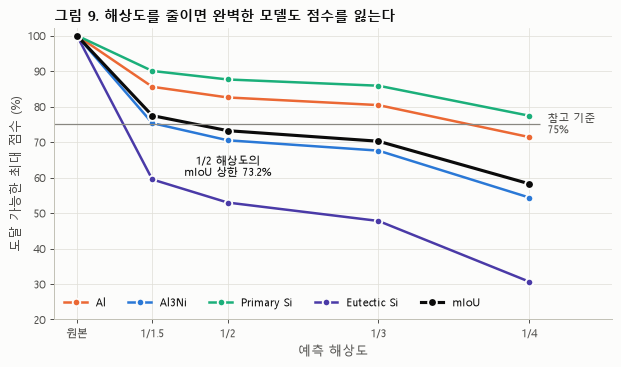

In [21]:
ks = [1, 1.5, 2, 3, 4]
fig, ax = plt.subplots(figsize=(8, 4.2))
for c, s in enumerate(SHORT):
    y = [100] + [np.nanmean(ceil[k][:, c]) * 100 for k in ks[1:]]
    ax.plot(ks, y, color=PALETTE[s], linewidth=2, marker='o', markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5, label=CLASSES[c])
y = [100] + [np.nanmean(np.nanmean(ceil[k], 1)) * 100 for k in ks[1:]]
ax.plot(ks, y, color=INK, linewidth=2.5, marker='o', markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label='mIoU')
ax.text(2, 63, f'1/2 해상도의\nmIoU 상한 {y[2]:.1f}%', ha='center', va='center', fontsize=9, color=INK)
ax.hlines(75, 0.85, 4.07, color=MUTED, linewidth=1)
ax.text(4.12, 75, '참고 기준\n75%', va='center', fontsize=9, color=INK2)
ax.set_xlim(0.85, 4.55)
ax.set_xticks(ks, ['원본', '1/1.5', '1/2', '1/3', '1/4'])
ax.set_xlabel('예측 해상도'); ax.set_ylabel('도달 가능한 최대 점수 (%)'); ax.set_ylim(20, 102)
ax.legend(loc='lower left', ncol=5)
ax.set_title('그림 9. 해상도를 줄이면 완벽한 모델도 점수를 잃는다')
fig.savefig(FIG / 'fig09_resolution_ceiling.png'); plt.show()

**해석**
- 밝기만 쓰는 방법은 정답을 보고 기준을 골라도 약 65%에서 멈춥니다. Eutectic Si는 30% 수준입니다. 주변 모양까지 보는 **딥러닝 분할 모델이 꼭 필요합니다.**
- 정답 마스크를 1/2로 줄였다 되돌리기만 해도 참고 기준(75%) 아래로 떨어집니다. 실제 모델은 부드럽게 확대하므로 이보다 조금 낫겠지만, 방향은 분명합니다.
- **결정:** 원본 해상도(또는 더 크게 키운 해상도)로 학습하고 예측합니다. GPU 메모리에 맞춰 이미지를 조각(타일)으로 잘라 처리합니다.

## 10. 기타 점검

In [22]:
# 중복·유사 이미지: 축소 이미지 간 상관계수
th = np.array([cv2.resize(r['gray'], (64, 45), interpolation=cv2.INTER_AREA).astype(float).ravel() for r in records])
th = (th - th.mean(1, keepdims=True)) / th.std(1, keepdims=True)
C = th @ th.T / th.shape[1]; np.fill_diagonal(C, -1)
iu = np.triu_indices(len(records), 1); top = np.argsort(-C[iu])[:5]
display(pd.DataFrame([{'유사도': C[iu[0][t], iu[1][t]], '이미지 1': f"{records[iu[0][t]]['split']}:{records[iu[0][t]]['name']}",
                       '이미지 2': f"{records[iu[1][t]]['split']}:{records[iu[1][t]]['name']}"} for t in top]).round(2))

# 가장자리 2px와 내부의 상 비율 비교
b, inn = np.zeros(4), np.zeros(4)
for r in labeled:
    m = np.ones(r['lab'].shape, bool); m[2:-2, 2:-2] = False
    b += np.bincount(r['lab'][m], minlength=4); inn += np.bincount(r['lab'][~m], minlength=4)
display(pd.DataFrame({'가장자리 2px(%)': b / b.sum() * 100, '내부(%)': inn / inn.sum() * 100}, index=CLASSES).T)

,유사도,이미지 1,이미지 2
0,0.3,train:A139_step4_sample3,train:A155_step3_sample2
1,0.3,train:A69_step4_sample4,valid:A117_step4_sample2
2,0.3,train:A155_step3_sample2,train:A51_step4_sample4
3,0.2,train:A18_step2_sample1,test:A133_step4_sample1
4,0.2,train:A111_step3_sample4,train:A21_step2_sample4


,Al,Al3Ni,Primary Si,Eutectic Si
가장자리 2px(%),56.4,25.0,8.0,10.6
내부(%),58.0,25.3,9.6,7.1


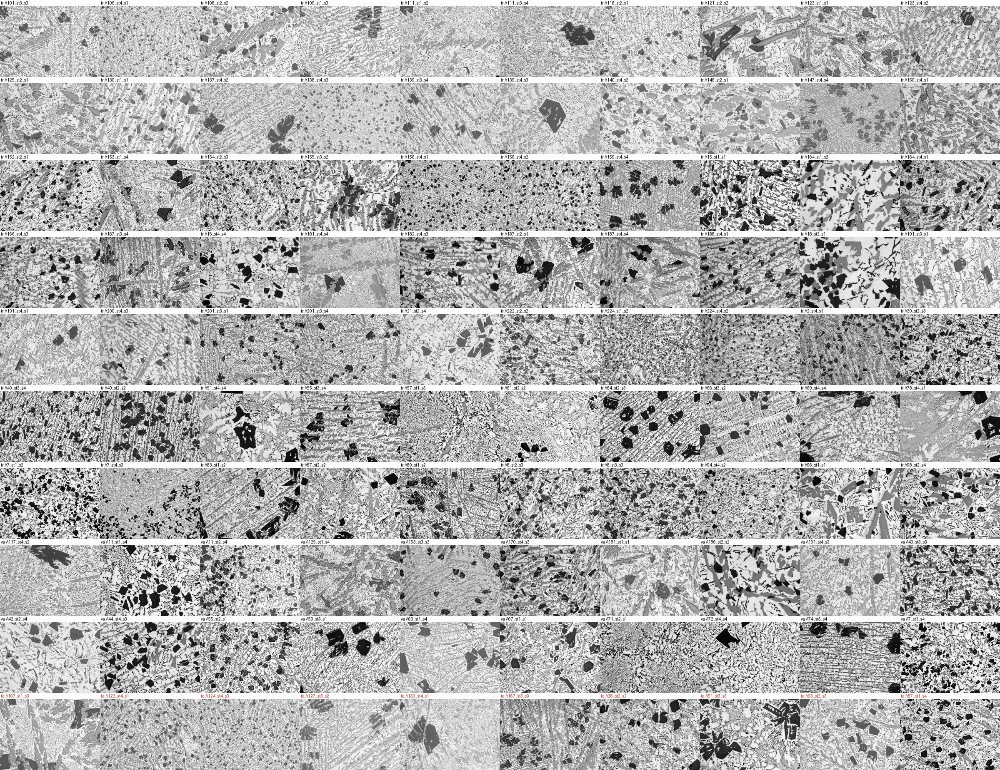

In [23]:
tw, th_, cols = 240, 171, 10
sheet = Image.new('RGB', (cols * tw, ((len(records) + cols - 1) // cols) * (th_ + 14)), SURFACE)
d = ImageDraw.Draw(sheet)
for i, r in enumerate(records):
    x, y = (i % cols) * tw, (i // cols) * (th_ + 14)
    sheet.paste(Image.fromarray(r['gray']).convert('RGB').resize((tw, th_)), (x, y + 14))
    d.text((x + 2, y + 1), f"{r['split'][:2]} {r['name']}".replace('_sample', '_s').replace('_step', '_st'),
           fill=(208, 59, 59) if r['split'] == 'test' else (11, 11, 11))
sheet.save(FIG / 'fig10_all_images.jpg', quality=88)
display(IPImage(filename=str(FIG / 'fig10_all_images.jpg'), width=1000))

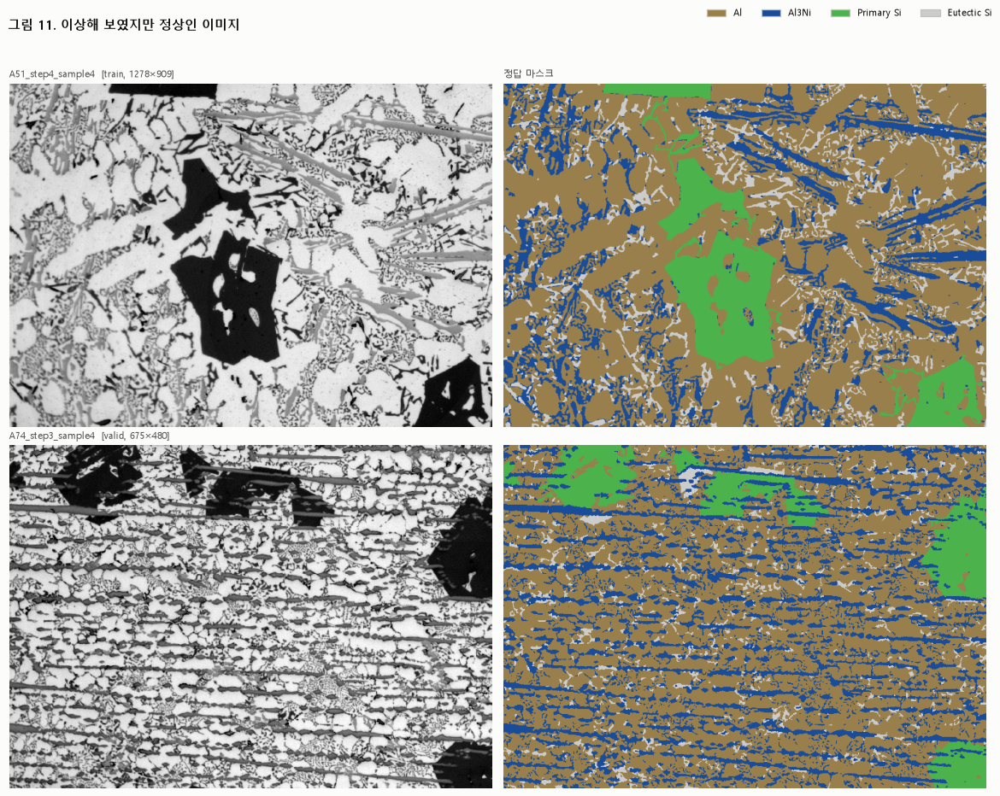

In [24]:
show_rows(['A51_step4_sample4', 'A74_step3_sample4'], 'fig11_odd_looking.png', '그림 11. 이상해 보였지만 정상인 이미지', overlay=False)

**해석**
- 그림 10은 전체 100장입니다(빨간 이름 = 평가용). 스케일바나 글자 같은 이물질은 없습니다.
- 서로 거의 같은 사진(중복)은 없습니다. 유사도가 가장 높은 쌍도 0.3 수준이라 데이터 누수 걱정이 없습니다.
- 가장자리 픽셀의 상 비율은 내부와 비슷합니다(Eutectic Si만 약간 많음). 가장자리 라벨에 특별한 문제는 없습니다.
- A51 위쪽 검은 띠는 가장자리에 걸친 Primary Si이고, A74 가로줄은 한 방향으로 자란 Al3Ni입니다. 라벨도 맞습니다.

## 11. 결론: 발견 → 결정

| # | 발견 | 근거 | 모델링 결정 |
|---|---|---|---|
| 1 | 평가 세트에 저대비 이미지가 몰려 있음 | 저대비 비율: 학습 33%, 검증 25%, **평가 60%** (5절) | p1–p99 밝기 정규화 기본 적용, 대비 증강, 저대비 검증 점수 별도 확인 |
| 2 | 해상도를 줄이면 상한이 급락 | 완벽한 모델도 1/2 해상도에서 기준 75% 미만 (9절) | 원본 이상 해상도로 타일 학습·예측 |
| 3 | 같은 시야를 해상도만 다르게 촬영, 작은 사진의 구조는 약 2px | 상대 크기 일정, 675px 사진 두께 약 1.9px (4절) | 모든 이미지를 같은 배율로 맞춰 처리 후 원래 크기로 복원 |
| 4 | Eutectic Si가 가장 어려움 | 면적 약 7%, 가늘고, 밝기 규칙 상한 약 30% (3·9절) | 경계 가중·IoU 직접 최적화 손실, 고해상도 디코더 |
| 5 | Primary Si가 없는 이미지 존재 | 잘못 칠하면 이미지 점수 약 75%로 하락 (7절) | 작은 조각 제거(0.01%), 전체 0.5% 미만이면 제거 |
| 6 | Primary Si와 Eutectic Si는 거의 맞닿지 않음 | 경계 1,260만 픽셀 중 수백 개 (8절) | 구조 규칙 기반 후처리·손실 실험 (독창성 후보) |
| 7 | 밝기만으로는 한계 | 정답을 써도 약 65% (9절) | 문맥을 보는 딥러닝 분할 모델 사용 |
| 8 | Step이 상 비율에 영향 | 같은 합금 10쌍 중 9쌍에서 Al3Ni 증가, Eutectic Si 감소 (6절) | Step별 검증, Step 조건 입력 실험, 인사이트로 활용 |
| 9 | 같은 합금 사진은 서로 비슷 | 세트 간 합금 공유 (1절) | 합금 번호 단위 교차검증 |
| 10 | 조명 불균일 | 모서리가 가운데보다 약 10 어두움 (5절) | 조명 기울기 증강 |
| 11 | 라벨·정렬 품질 양호, 중복 없음 | 4색 외 픽셀 0, 어긋남 0 (2·10절) | 별도 라벨 정제 불필요 |